<a href="https://colab.research.google.com/github/jms011208/zero_DCE/blob/improve%2Fdenoise-net/zero_DCE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/jms011208/zero_DCE.git
%cd zero_DCE

# 학습용 데이터 (73MB)
!pip install -q gdown
!gdown 1GAB3uGsmAyLgtDBDONbil08vVu5wJcG3 -O train_data.zip
!unzip -q train_data.zip -d data/

# 테스트 이미지(DICM, LIME)는 원본 저장소에서 가져오기
!git clone -q --depth 1 https://github.com/Li-Chongyi/Zero-DCE.git /tmp/zdce
!cp -r /tmp/zdce/Zero-DCE_code/data/test_data data/

Cloning into 'zero_DCE'...
remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (32/32), done.
remote: Total 42 (delta 15), reused 36 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (42/42), 981.40 KiB | 36.35 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/content/zero_DCE
Downloading...
From (original): https://drive.google.com/uc?id=1GAB3uGsmAyLgtDBDONbil08vVu5wJcG3
From (redirected): https://drive.google.com/uc?id=1GAB3uGsmAyLgtDBDONbil08vVu5wJcG3&confirm=t&uuid=3c4d79d5-710c-41d5-a19a-9e7738bd8078
To: /content/zero_DCE/train_data.zip
100% 72.9M/72.9M [00:00<00:00, 80.1MB/s]


In [ ]:
!python lowlight_test.py

data/test_data/DICM/26.jpg
4.244668483734131
data/test_data/DICM/44.jpg
0.004744768142700195
data/test_data/DICM/61.jpg
0.014365911483764648
data/test_data/DICM/38.jpg
0.0033469200134277344
data/test_data/DICM/33.jpg
0.01722240447998047
data/test_data/DICM/04.jpg
0.001994609832763672
data/test_data/DICM/65.jpg
0.0031671524047851562
data/test_data/DICM/46.jpg
0.002994537353515625
data/test_data/DICM/01.jpg
0.006216764450073242
data/test_data/DICM/13.jpg
0.006669282913208008
data/test_data/DICM/54.jpg
0.0018749237060546875
data/test_data/DICM/53.jpg
0.0018053054809570312
data/test_data/DICM/55.jpg
0.0020389556884765625
data/test_data/DICM/62.jpg
0.0019469261169433594
data/test_data/DICM/36.jpg
0.005018949508666992
data/test_data/DICM/20.jpg
0.0018200874328613281
data/test_data/DICM/47.jpg
0.0018339157104492188
data/test_data/DICM/40.jpg
0.002904653549194336
data/test_data/DICM/18.jpg
0.0018677711486816406
data/test_data/DICM/27.jpg
0.0017507076263427734
data/test_data/DICM/35.jpg
0.00494

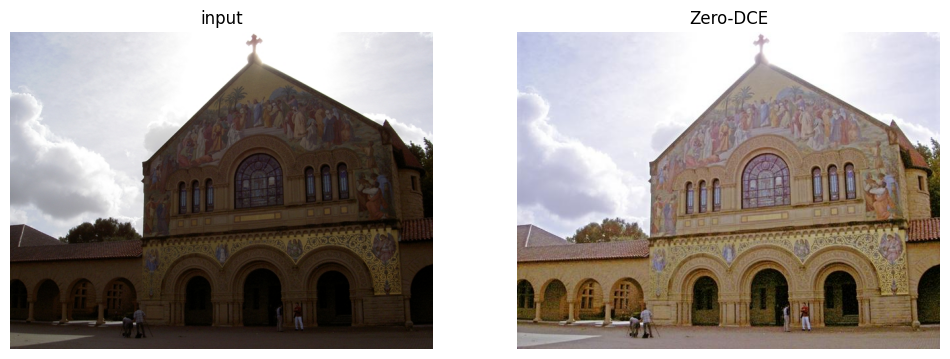

In [ ]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
name = "DICM/04.jpg"   # 보고 싶은 파일
a = mpimg.imread(f"data/test_data/{name}")
b = mpimg.imread(f"data/result/{name}")
plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.imshow(a); plt.title("input"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(b); plt.title("Zero-DCE"); plt.axis("off")
plt.show()

In [ ]:
!git clone -b improve/denoise-net https://github.com/jms011208/zero_DCE.git
%cd zero_DCE
# (데이터 준비는 이전 안내 그대로)
!python lowlight_train_v2.py --num_epochs 30
!python eval_lol.py --lol_dir data/LOL/eval15
!python lowlight_test_v2.py --save_extra

Cloning into 'zero_DCE'...
remote: Enumerating objects: 49, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 49 (delta 20), reused 40 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (49/49), 988.75 KiB | 1002.00 KiB/s, done.
Resolving deltas: 100% (20/20), done.
/content/zero_DCE/zero_DCE
device: cuda
denoiser params: 5812
Total training examples: 0
Traceback (most recent call last):
  File "/content/zero_DCE/zero_DCE/lowlight_train_v2.py", line 175, in <module>
    train(parser.parse_args())
    ~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/content/zero_DCE/zero_DCE/lowlight_train_v2.py", line 101, in train
    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=config.train_batch_size, shuffle=True,
        num_workers=config.num_workers, pin_memory=(device.type == "cuda"))
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 401, in __init__
    sampler = Ran

In [ ]:
%cd /content
!rm -rf zero_DCE
!git clone -b improve/denoise-net https://github.com/jms011208/zero_DCE.git
%cd /content/zero_DCE

!pip install -q gdown
!gdown 1GAB3uGsmAyLgtDBDONbil08vVu5wJcG3 -O train_data.zip
!unzip -q train_data.zip -d data/

!wget -q -O lol.zip https://huggingface.co/datasets/geekyrakshit/LoL-Dataset/resolve/main/lol_dataset.zip
!unzip -q lol.zip -d data/ && mv data/lol_dataset data/LOL

!git clone -q --depth 1 https://github.com/Li-Chongyi/Zero-DCE.git /tmp/zdce
!cp -r /tmp/zdce/Zero-DCE_code/data/test_data data/

/content
Cloning into 'zero_DCE'...
remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (32/32), done.
remote: Total 42 (delta 15), reused 36 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (42/42), 981.40 KiB | 1.23 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/content/zero_DCE
Downloading...
From (original): https://drive.google.com/uc?id=1GAB3uGsmAyLgtDBDONbil08vVu5wJcG3
From (redirected): https://drive.google.com/uc?id=1GAB3uGsmAyLgtDBDONbil08vVu5wJcG3&confirm=t&uuid=4fa2f4da-0bdb-4924-8148-e55a5bdc85f7
To: /content/zero_DCE/train_data.zip
100% 72.9M/72.9M [00:00<00:00, 75.0MB/s]
fatal: destination path '/tmp/zdce' already exists and is not an empty directory.


In [ ]:
!pwd
!ls data/train_data | wc -l       # 2002가 나와야 합니다
!ls data/LOL/eval15               # high, low가 보여야 합니다

/content/zero_DCE
2002
high  low


In [ ]:
!python lowlight_train_v2.py --num_epochs 30
!python eval_lol.py --lol_dir data/LOL/eval15
!python lowlight_test_v2.py --save_extra

device: cuda
denoiser params: 5812
Total training examples: 2002
epoch 0 iter 50 | loss 0.0416 (rec 0.0346, grad 0.0000, mask 0.0694) | L1 before 0.0346 -> after 0.0346
epoch 0 iter 100 | loss 0.0476 (rec 0.0382, grad 0.0000, mask 0.0935) | L1 before 0.0379 -> after 0.0382
epoch 0 iter 150 | loss 0.0481 (rec 0.0354, grad 0.0000, mask 0.1271) | L1 before 0.0356 -> after 0.0354
epoch 0 iter 200 | loss 0.0423 (rec 0.0366, grad 0.0000, mask 0.0568) | L1 before 0.0377 -> after 0.0366
epoch 0 iter 250 | loss 0.0510 (rec 0.0480, grad 0.0000, mask 0.0298) | L1 before 0.0496 -> after 0.0480
epoch 1 iter 50 | loss 0.0488 (rec 0.0367, grad 0.0000, mask 0.1207) | L1 before 0.0371 -> after 0.0367
epoch 1 iter 100 | loss 0.0499 (rec 0.0383, grad 0.0000, mask 0.1158) | L1 before 0.0391 -> after 0.0383
epoch 1 iter 150 | loss 0.0448 (rec 0.0404, grad 0.0000, mask 0.0442) | L1 before 0.0424 -> after 0.0404
epoch 1 iter 200 | loss 0.0449 (rec 0.0338, grad 0.0000, mask 0.1110) | L1 before 0.0354 -> after

In [ ]:
%cd /content/zero_DCE
!python lowlight_test_v2.py --input data/LOL/eval15/low --output data/result_lol/ --save_extra

/content/zero_DCE
device: cuda | images: 15
1.png  (0.502s)
111.png  (0.003s)
146.png  (0.004s)
179.png  (0.002s)
22.png  (0.003s)
23.png  (0.003s)
493.png  (0.003s)
547.png  (0.003s)
55.png  (0.003s)
665.png  (0.003s)
669.png  (0.003s)
748.png  (0.002s)
778.png  (0.002s)
780.png  (0.003s)
79.png  (0.002s)


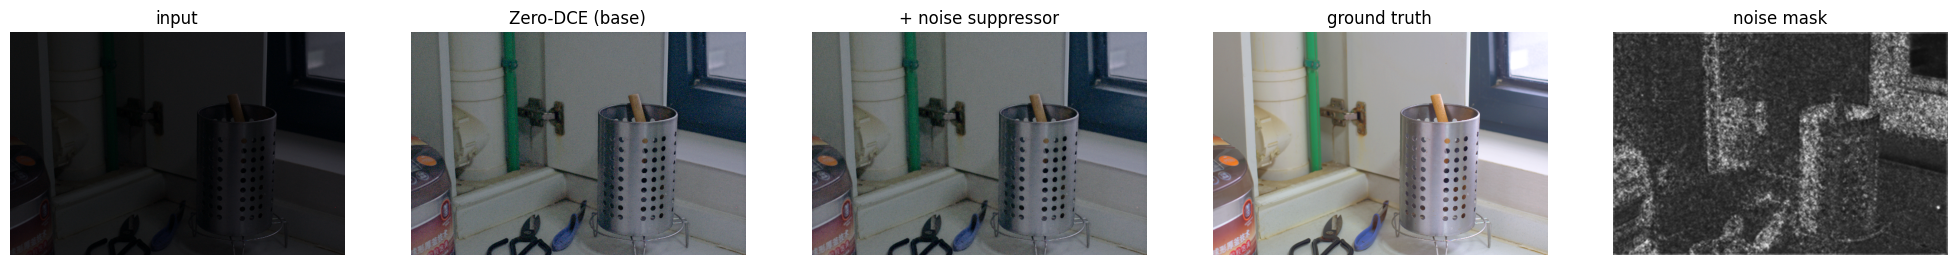

In [ ]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
n = "111"
items = [("input", f"data/LOL/eval15/low/{n}.png"),
         ("Zero-DCE (base)", f"data/result_lol/{n}_base.png"),
         ("+ noise suppressor", f"data/result_lol/{n}.png"),
         ("ground truth", f"data/LOL/eval15/high/{n}.png"),
         ("noise mask", f"data/result_lol/{n}_mask.png")]
fig, ax = plt.subplots(1, 5, figsize=(25, 4))
for a, (t, p) in zip(ax, items):
    im = mpimg.imread(p); a.imshow(im, cmap="gray" if im.ndim == 2 else None); a.set_title(t); a.axis("off")
plt.show()

In [ ]:
%cd /content/zero_DCE
!git pull
!python lowlight_train_v2.py --help | grep lam_edge     # 옵션이 보이면 정상

/content/zero_DCE
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 7 (delta 5), reused 7 (delta 5), pack-reused 0 (from 0)
Unpacking objects: 100% (7/7), 7.96 KiB | 2.65 MiB/s, done.
From https://github.com/jms011208/zero_DCE
   cdc2ddb..9ad2799  improve/denoise-net -> origin/improve/denoise-net
Updating cdc2ddb..9ad2799
Fast-forward
 README.md                                          |  10 +
 compare_denoise.py                                 | 246 +++++++++++++++++++++
 ...247\204\355\226\211\354\202\254\355\225\255.md" |   7 +
 ...210\230\354\240\225\354\202\254\355\225\255.md" |  25 +++
 4 files changed, 288 insertions(+)
 create mode 100644 compare_denoise.py
                            [--lam_edge LAM_EDGE] [--lam_grad LAM_GRAD]
  --lam_edge LAM_EDGE   경계 픽셀 L1 가중치 추가분 (0=사용 안 함, 예: 4면 경계에서 5배)


In [ ]:
!python lowlight_train_v2.py --num_epochs 30 --lam_edge 4 --snapshots_folder snapshots/denoise_edge4/

device: cuda
denoiser params: 5812
Total training examples: 2002
epoch 0 iter 50 | loss 0.0418 (rec 0.0349, grad 0.0000, mask 0.0693) | L1 before 0.0346 -> after 0.0346
epoch 0 iter 100 | loss 0.0455 (rec 0.0361, grad 0.0000, mask 0.0947) | L1 before 0.0379 -> after 0.0377
epoch 0 iter 150 | loss 0.0467 (rec 0.0340, grad 0.0000, mask 0.1270) | L1 before 0.0356 -> after 0.0353
epoch 0 iter 200 | loss 0.0416 (rec 0.0360, grad 0.0000, mask 0.0566) | L1 before 0.0377 -> after 0.0367
epoch 0 iter 250 | loss 0.0509 (rec 0.0480, grad 0.0000, mask 0.0295) | L1 before 0.0496 -> after 0.0480
epoch 1 iter 50 | loss 0.0485 (rec 0.0363, grad 0.0000, mask 0.1220) | L1 before 0.0371 -> after 0.0364
epoch 1 iter 100 | loss 0.0514 (rec 0.0399, grad 0.0000, mask 0.1159) | L1 before 0.0391 -> after 0.0377
epoch 1 iter 150 | loss 0.0450 (rec 0.0406, grad 0.0000, mask 0.0436) | L1 before 0.0424 -> after 0.0403
epoch 1 iter 200 | loss 0.0447 (rec 0.0338, grad 0.0000, mask 0.1095) | L1 before 0.0354 -> after

In [ ]:
!python eval_lol.py --denoise_weights snapshots/denoise_v1/denoiser_latest.pth
!python eval_lol.py --denoise_weights snapshots/denoise_edge4/denoiser_latest.pth

image        PSNR base SSIM base |  PSNR +dn  SSIM +dn
1.png           13.806    0.6923 |    13.943    0.7401
111.png         12.647    0.6243 |    12.934    0.6899
146.png         15.478    0.7246 |    15.710    0.7475
179.png         20.219    0.6977 |    19.581    0.7020
22.png          13.128    0.6325 |    13.306    0.6672
23.png           8.259    0.3465 |     8.319    0.3772
493.png         18.077    0.5705 |    18.091    0.5782
547.png         19.716    0.6003 |    20.322    0.6789
55.png           7.979    0.3349 |     8.023    0.3660
665.png         10.791    0.3633 |    10.900    0.4145
669.png         14.635    0.5704 |    15.107    0.6475
748.png         20.005    0.6409 |    20.607    0.7125
778.png         13.848    0.4609 |    13.815    0.4490
780.png         22.461    0.5436 |    22.811    0.6256
79.png          11.869    0.6372 |    12.122    0.6938
mean(15)        14.861    0.5627 |    15.039    0.6060
PSNR diff: +0.178 dB | SSIM diff: +0.0433
image        PSNR base 

In [ ]:
!python lowlight_test_v2.py --input data/LOL/eval15/low --output data/result_edge4/ --denoise_weights snapshots/denoise_edge4/denoiser_latest.pth --save_extra

device: cuda | images: 15
1.png  (0.358s)
111.png  (0.003s)
146.png  (0.002s)
179.png  (0.002s)
22.png  (0.002s)
23.png  (0.002s)
493.png  (0.002s)
547.png  (0.003s)
55.png  (0.002s)
665.png  (0.002s)
669.png  (0.002s)
748.png  (0.002s)
778.png  (0.002s)
780.png  (0.002s)
79.png  (0.002s)


In [ ]:
%cd /content/zero_DCE
import os, torch, numpy as np, torch.nn.functional as F, torchvision
from lowlight_test_v2 import build_net, load_image, pick_device

device = pick_device()
WEIGHTS = "snapshots/denoise_edge4/denoiser_latest.pth"   # 비교할 가중치 경로로 바꾸세요
net = build_net("snapshots/Epoch99.pth", WEIGHTS, device)

def rgb2ycc(x):
    r, g, b = x[:, 0:1], x[:, 1:2], x[:, 2:3]
    y = 0.299*r + 0.587*g + 0.114*b
    return y, 0.564*(b - y), 0.713*(r - y)          # Y(밝기), Cb, Cr(색)

def ycc2rgb(y, cb, cr):
    return torch.cat([y + 1.403*cr, y - 0.344*cb - 0.714*cr, y + 1.773*cb], 1).clamp(0, 1)

def blur(t, k):
    return t if k <= 1 else F.avg_pool2d(F.pad(t, (k//2,)*4, mode="replicate"), k, 1)

def ycc_combine(e, out, luma=0.0, chroma=1.0, chroma_blur=1):
    """e: 기존 Zero-DCE 결과, out: 노이즈 억제 결과
    luma: 밝기 채널에 노이즈 억제를 얼마나 반영할지 (0=보정 전 그대로 -> 경계 보존)
    chroma: 색 채널에 노이즈 억제를 얼마나 반영할지 (1=전부)
    chroma_blur: 색 채널만 추가로 k x k 평균 (1=안 함, 3 또는 5 추천)"""
    ye, cbe, cre = rgb2ycc(e); yo, cbo, cro = rgb2ycc(out)
    y  = (1 - luma) * ye + luma * yo
    cb = (1 - chroma) * cbe + chroma * cbo
    cr = (1 - chroma) * cre + chroma * cro
    return ycc2rgb(y, blur(cb, chroma_blur), blur(cr, chroma_blur))

def run(path):
    x = load_image(path, device)
    with torch.no_grad():
        _, e, _ = net.dce(x); out, m, _ = net.denoise(e, x)
    return e, out

/content/zero_DCE


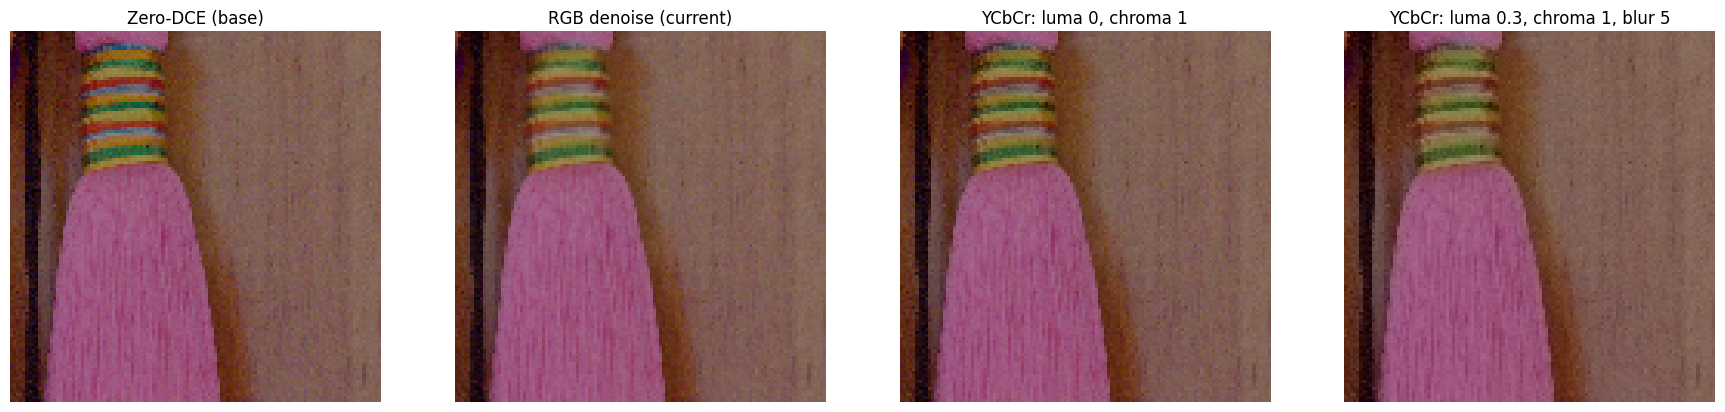

In [ ]:
import matplotlib.pyplot as plt
n = "179"
e, out = run(f"data/LOL/eval15/low/{n}.png")
variants = [("Zero-DCE (base)", e),
            ("RGB denoise (current)", out),
            ("YCbCr: luma 0, chroma 1", ycc_combine(e, out, 0.0, 1.0, 1)),
            ("YCbCr: luma 0.3, chroma 1, blur 5", ycc_combine(e, out, 0.3, 1.0, 5))]
y0, x0, s = 150, 250, 120          # 확대할 위치 (경계가 보이는 곳으로 조정)
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
for a, (t, img) in zip(ax, variants):
    a.imshow(img.squeeze(0).permute(1, 2, 0).cpu().numpy()[y0:y0+s, x0:x0+s], interpolation="nearest")
    a.set_title(t); a.axis("off")
plt.show()

In [ ]:
LUMA, CHROMA, CBLUR = 0.3, 1.0, 5        # 셀 2에서 고른 값
src, dst = "data/LOL/eval15/low", "data/result_ycc"
os.makedirs(dst, exist_ok=True)
for fn in sorted(os.listdir(src)):
    if fn.lower().endswith((".png", ".jpg", ".bmp")):
        e, out = run(f"{src}/{fn}")
        torchvision.utils.save_image(ycc_combine(e, out, LUMA, CHROMA, CBLUR),
                                     f"{dst}/{os.path.splitext(fn)[0]}.png")

In [ ]:
%cd /content/zero_DCE
import cv2, numpy as np, torch
from lowlight_test_v2 import build_net, load_image, pick_device
from model_v2 import gain_map

device = pick_device()
net = build_net("snapshots/Epoch99.pth", None, device)   # 노이즈 억제망 없이 Zero-DCE만

n = "179"
x = load_image(f"data/LOL/eval15/low/{n}.png", device)
with torch.no_grad():
    _, e, _ = net.dce(x)
    g = gain_map(x, e).squeeze().cpu().numpy()            # 0~1, 많이 밝아진 곳일수록 큼
E = (e.squeeze(0).permute(1, 2, 0).clamp(0, 1).cpu().numpy() * 255).astype(np.uint8)

# 고정 수식 노이즈 제거: 비지역 평균 (h=밝기 세기, hColor=색 세기)
F_ = cv2.fastNlMeansDenoisingColored(cv2.cvtColor(E, cv2.COLOR_RGB2BGR), None, h=6, hColor=12,
                                     templateWindowSize=7, searchWindowSize=21)
F_ = cv2.cvtColor(F_, cv2.COLOR_BGR2RGB)

# 많이 밝아진 곳만 강하게 적용
w = np.clip((g - g.min()) / (g.max() - g.min() + 1e-6), 0, 1)[..., None]
out = ((1 - w) * E + w * F_).astype(np.uint8)
cv2.imwrite(f"data/{n}_nlm.png", cv2.cvtColor(out, cv2.COLOR_RGB2BGR))

[Errno 2] No such file or directory: '/content/zero_DCE'
/content


ModuleNotFoundError: No module named 'lowlight_test_v2'

In [ ]:
%cd /content/zero_DCE
import cv2, numpy as np, torch
from lowlight_test_v2 import build_net, load_image, pick_device
from model_v2 import gain_map

device = pick_device()
net = build_net("snapshots/Epoch99.pth", None, device)   # 노이즈 억제망 없이 Zero-DCE만

n = "179"
x = load_image(f"data/LOL/eval15/low/{n}.png", device)
with torch.no_grad():
    _, e, _ = net.dce(x)
    g = gain_map(x, e).squeeze().cpu().numpy()            # 0~1, 많이 밝아진 곳일수록 큼
E = (e.squeeze(0).permute(1, 2, 0).clamp(0, 1).cpu().numpy() * 255).astype(np.uint8)

# 고정 수식 노이즈 제거: 비지역 평균 (h=밝기 세기, hColor=색 세기)
F_ = cv2.fastNlMeansDenoisingColored(cv2.cvtColor(E, cv2.COLOR_RGB2BGR), None, h=6, hColor=12,
                                     templateWindowSize=7, searchWindowSize=21)
F_ = cv2.cvtColor(F_, cv2.COLOR_BGR2RGB)

# 많이 밝아진 곳만 강하게 적용
w = np.clip((g - g.min()) / (g.max() - g.min() + 1e-6), 0, 1)[..., None]
out = ((1 - w) * E + w * F_).astype(np.uint8)
cv2.imwrite(f"data/{n}_nlm.png", cv2.cvtColor(out, cv2.COLOR_RGB2BGR))

/content/zero_DCE


True

In [ ]:
%cd /content/zero_DCE
!git pull
!pip install -q bm3d
!python compare_denoise.py --cnn_weights snapshots/denoise_edge4/denoiser_latest.pth --save_dir data/result_compare

/content/zero_DCE
Already up to date.
device: cuda | images: 15 | methods: base,cnn,nlm,bilateral,guided,bm3d | adaptive: False
done: 1.png (Zero-DCE 0.29s)
done: 111.png (Zero-DCE 0.00s)
done: 146.png (Zero-DCE 0.00s)
done: 179.png (Zero-DCE 0.00s)
done: 22.png (Zero-DCE 0.00s)
done: 23.png (Zero-DCE 0.00s)
done: 493.png (Zero-DCE 0.00s)
done: 547.png (Zero-DCE 0.00s)
done: 55.png (Zero-DCE 0.00s)
done: 665.png (Zero-DCE 0.00s)
done: 669.png (Zero-DCE 0.00s)
done: 748.png (Zero-DCE 0.00s)
done: 778.png (Zero-DCE 0.00s)
done: 780.png (Zero-DCE 0.00s)
done: 79.png (Zero-DCE 0.00s)

method         PSNR     SSIM  edge_ratio  flat_luma  flat_chroma      sec
base         14.861   0.5627       1.000      23.66        34.37     0.00
cnn          15.055   0.6073       0.987      19.28        21.18     0.01
nlm          14.850   0.6787       0.977      14.68         6.71     0.68
bilateral    15.009   0.6915       0.959      13.78        12.40     0.04
guided       14.889   0.6761       0.785  

In [ ]:
!python compare_denoise.py --methods base,cnn,nlm,bilateral,guided --cnn_weights snapshots/denoise_edge4/denoiser_latest.pth --nlm_h 3 --nlm_h_color 8 --bil_sigma_color 0.05 --gf_eps 0.001 --csv data/cmp_weak.csv

device: cuda | images: 15 | methods: base,cnn,nlm,bilateral,guided | adaptive: False
done: 1.png (Zero-DCE 0.33s)
done: 111.png (Zero-DCE 0.00s)
done: 146.png (Zero-DCE 0.00s)
done: 179.png (Zero-DCE 0.00s)
done: 22.png (Zero-DCE 0.00s)
done: 23.png (Zero-DCE 0.00s)
done: 493.png (Zero-DCE 0.00s)
done: 547.png (Zero-DCE 0.00s)
done: 55.png (Zero-DCE 0.00s)
done: 665.png (Zero-DCE 0.00s)
done: 669.png (Zero-DCE 0.00s)
done: 748.png (Zero-DCE 0.00s)
done: 778.png (Zero-DCE 0.00s)
done: 780.png (Zero-DCE 0.00s)
done: 79.png (Zero-DCE 0.00s)

method         PSNR     SSIM  edge_ratio  flat_luma  flat_chroma      sec
base         14.861   0.5627       1.000      23.66        34.37     0.00
cnn          15.055   0.6073       0.987      19.28        21.18     0.01
nlm          14.871   0.6599       0.988      19.69        13.32     0.66
bilateral    14.949   0.6443       0.987      18.75        22.48     0.03
guided       14.927   0.6815       0.920      13.92         6.20     0.02

(n=15) edg

In [ ]:
%cd /content/zero_DCE
!git pull
!python compare_denoise.py --cnn_weights snapshots/denoise_edge4/denoiser_latest.pth
!python compare_denoise.py --methods base,cnn,ycc_nlm,ycc_bilateral,ycc_guided --ycc_luma 0.3 --cnn_weights snapshots/denoise_edge4/denoiser_latest.pth --csv data/cmp_ycc03.csv

/content/zero_DCE
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 7 (delta 6), reused 7 (delta 6), pack-reused 0 (from 0)
Unpacking objects: 100% (7/7), 5.71 KiB | 1.43 MiB/s, done.
From https://github.com/jms011208/zero_DCE
   9ad2799..deb92af  improve/denoise-net -> origin/improve/denoise-net
Updating 9ad2799..deb92af
Fast-forward
 README.md                                          |  1 +
 compare_denoise.py                                 | 53 ++++++++++++---
 ...247\204\355\226\211\354\202\254\355\225\255.md" | 12 +++-
 ...210\230\354\240\225\354\202\254\355\225\255.md" | 76 +++++++++++++++++++++-
 4 files changed, 128 insertions(+), 14 deletions(-)
device: cuda | images: 15 | methods: base,cnn,nlm,bilateral,guided,bm3d,ycc_nlm,ycc_bilateral,ycc_guided | adaptive: False | ycc_luma: 0.00
done: 1.png (Zero-DCE 0.29s)
done: 111.png (Zero-DCE 0.00s)
done: 146.png (Zero-DCE 0.00s)
done: 179

In [ ]:
!python compare_denoise.py --methods base,cnn,nlm,ycc_nlm,ycc_bilateral --ycc_luma 0.3 --cnn_weights snapshots/denoise_edge4/denoiser_latest.pth --save_dir data/result_ycc03 --csv data/cmp_ycc03.csv

device: cuda | images: 15 | methods: base,cnn,nlm,ycc_nlm,ycc_bilateral | adaptive: False | ycc_luma: 0.30
done: 1.png (Zero-DCE 0.31s)
done: 111.png (Zero-DCE 0.00s)
done: 146.png (Zero-DCE 0.00s)
done: 179.png (Zero-DCE 0.00s)
done: 22.png (Zero-DCE 0.00s)
done: 23.png (Zero-DCE 0.00s)
done: 493.png (Zero-DCE 0.00s)
done: 547.png (Zero-DCE 0.00s)
done: 55.png (Zero-DCE 0.00s)
done: 665.png (Zero-DCE 0.00s)
done: 669.png (Zero-DCE 0.00s)
done: 748.png (Zero-DCE 0.00s)
done: 778.png (Zero-DCE 0.00s)
done: 780.png (Zero-DCE 0.00s)
done: 79.png (Zero-DCE 0.00s)

method             PSNR     SSIM  edge_ratio  flat_luma  flat_chroma      sec
base             14.861   0.5627       1.000      23.66        34.37     0.00
cnn              15.055   0.6073       0.987      19.28        21.18     0.01
nlm              14.850   0.6787       0.977      14.68         6.71     0.72
ycc_nlm          14.886   0.6469       0.986      19.98         6.78     0.73
ycc_bilateral    14.976   0.6528       0.98